# Neural Network cho Caro 11×11
## Task 1 — Sinh dữ liệu tự đấu
Tác tử `tactical-v1` chơi cả hai bên. Mỗi mẫu là bàn cờ trước khi đi và nước do tác tử chọn, dùng cho học có giám sát. Tác tử ưu tiên thắng ngay, chặn thua ngay, tạo nhiều ô thắng ở lượt sau rồi xét các đoạn quân chưa bị chặn. Một số nước mở đầu ngẫu nhiên được ghi trong log ván để phát lại và được bỏ khỏi tập nhãn.

In [1]:
from collections import defaultdict
import hashlib
import json
import os
from pathlib import Path

import numpy as np

# Chuyển về thư mục Caro để import module chung từ vị trí notebook.
if Path.cwd().name == 'notebooks' and (Path.cwd().parent / 'core').is_dir():
    os.chdir(Path.cwd().parent)
if not (Path.cwd() / 'core' / 'game_engine.py').is_file():
    raise RuntimeError('Hãy mở notebook từ thư mục caro-11x11 hoặc notebooks')
from core.game_engine import CaroGame
from training.dataset import SPLITS, PolicyDataset, canonical_key

data = Path('training/data/caro11-v1')
if not (data / 'manifest.json').is_file():
    raise FileNotFoundError('Hãy sinh dữ liệu bằng lệnh trong mục Tái lập bên dưới')
manifest = json.loads((data / 'manifest.json').read_text(encoding='utf-8'))

## Tái lập
Chạy từ thư mục `caro-11x11` trong PowerShell. Thư mục đích phải mới, vì trình sinh bảo vệ các bộ dữ liệu đã có.

```powershell
.\.venv\Scripts\python.exe -m training.generate_data --games 1000 --seed 42 --opening-plies 4
.\.venv\Scripts\python.exe -m pytest tests/test_neural_agent.py -q
```

Chia ván 80/10/10 theo seed. Chuẩn hóa theo người đến lượt, so trùng cả tám phép xoay/lật và giữ theo thứ tự test, validation, train. Khi huấn luyện có thể bật `PolicyDataset(data, 'train', augment=True)` để tăng cường trên train. Validation và test giữ nguyên.

In [2]:
for name, checksum in manifest['sha256'].items():
    with (data / name).open('rb') as file:
        assert hashlib.file_digest(file, 'sha256').hexdigest() == checksum

print(f"Nguồn nhãn: {manifest['teacher']} | Seed: {manifest['seed']} | Tổng ván: {manifest['games']}")
outcomes = manifest['outcomes']
print(f"X thắng: {outcomes['X']} | O thắng: {outcomes['O']} | Hòa: {outcomes['draw']}")
datasets = {split: PolicyDataset(data, split) for split in SPLITS}
for split, dataset in datasets.items():
    stats = manifest['splits'][split]
    print(f"{split}: {stats['games_assigned']} ván được chia, {stats['games_with_samples']} ván còn mẫu, "
          f"{len(dataset)} mẫu, loại {stats['removed_duplicates']} thế trùng")
features, label = datasets['train'][0]
print(f'Mẫu đọc cho CNN: kích thước {features.shape}, kiểu {features.dtype}, nhãn {label}')

Nguồn nhãn: tactical-v1 | Seed: 42 | Tổng ván: 1000
X thắng: 653 | O thắng: 333 | Hòa: 14
train: 800 ván được chia, 235 ván còn mẫu, 5380 mẫu, loại 11589 thế trùng
val: 100 ván được chia, 45 ván còn mẫu, 1205 mẫu, loại 1140 thế trùng
test: 100 ván được chia, 58 ván còn mẫu, 1042 mẫu, loại 856 thế trùng
Mẫu đọc cho CNN: kích thước (2, 11, 11), kiểu float32, nhãn 38


## Đối chiếu dữ liệu với engine
Kiểm tra mọi mẫu bằng cách phát lại các ván đã lưu. Nước đi phải trùng nhãn, bàn cờ phải là trạng thái trước nước đi và mỗi thế cờ chuẩn hóa chỉ được xuất hiện một lần qua các tập.

In [3]:
positions = defaultdict(dict)
unique_boards = set()
for split, dataset in datasets.items():
    for board, action, game_id, ply in zip(dataset.boards, dataset.actions, dataset.game_ids, dataset.plies):
        key = canonical_key(board)
        assert key not in unique_boards and ply not in positions[game_id]
        unique_boards.add(key)
        positions[game_id][ply] = (board, int(action), split)

seen_games = set()
with (data / 'games.jsonl').open(encoding='utf-8') as log:
    for line in log:
        record = json.loads(line)
        game_id = record['game_id']
        assert game_id not in seen_games
        seen_games.add(game_id)
        samples = positions.pop(game_id, {})
        game = CaroGame()
        for ply, move in enumerate(record['moves'], 1):
            if ply in samples:
                board, action, split = samples.pop(ply)
                assert ply > record['opening_plies'] and split == record['split']
                assert divmod(action, game.board_size) == tuple(move)
                np.testing.assert_array_equal(board, game.board * game.current_player)
            game.step(tuple(move))
        assert not samples and game.is_terminal() and game.result() == record['result']
assert not positions and len(seen_games) == manifest['games']
print(f'Đã phát lại {len(seen_games)} ván và đối chiếu {len(unique_boards)} mẫu. Tất cả đều hợp lệ.')

Đã phát lại 1000 ván và đối chiếu 7627 mẫu. Tất cả đều hợp lệ.


## Task 2 — Huấn luyện CNN Policy
Mạng nhận hai kênh 11×11, dùng bốn lớp tích chập 3×3 giữ nguyên kích thước bàn, rồi dùng lớp 1×1 để tạo logit cho 121 ô. Khi tính loss và xếp hạng, các ô đã có quân bị loại. Dùng Adam và chọn checkpoint theo validation loss thấp nhất.

```powershell
.\.venv\Scripts\python.exe -m training.train --output models/caro-policy-v1-retrain --device auto --epochs 20 --batch-size 64 --lr 0.001 --patience 5 --seed 42
```

Cell dưới đọc kết quả của lượt huấn luyện chính thức trong `models/caro-policy-v1/`. Nếu huấn luyện lại bằng lệnh trên, đổi biến `run` sang `models/caro-policy-v1-retrain/` để xem kết quả của lượt mới.

Thiết bị: NVIDIA GeForce GTX 1650 | Thời gian huấn luyện: 33.77 giây
Chọn epoch 7/12 | Validation loss: 0.9799
Test loss: 0.7036 | Top-1: 74.28% | Top-3: 96.07%
Checkpoint: 376,053 byte | 93,025 tham số


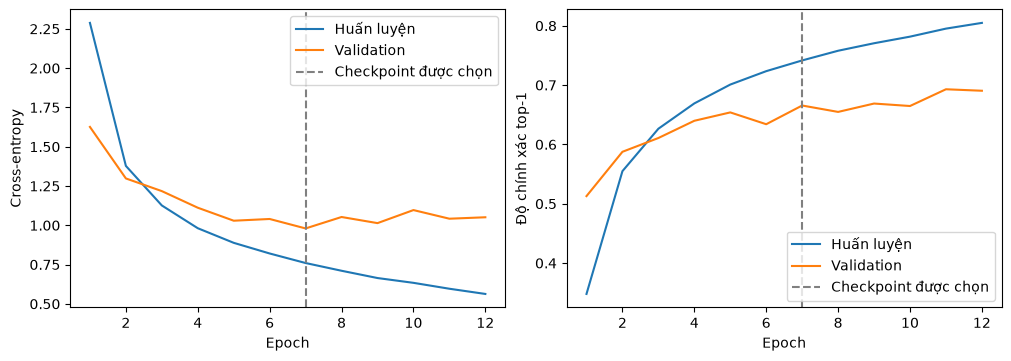

In [4]:
import matplotlib.pyplot as plt

run = Path('models/caro-policy-v1')
report_path = run / 'report.json'
if not report_path.is_file():
    raise FileNotFoundError('Hãy chạy lệnh huấn luyện ở mục Task 2 trước')
report = json.loads(report_path.read_text(encoding='utf-8'))
with (data / 'manifest.json').open('rb') as file:
    assert hashlib.file_digest(file, 'sha256').hexdigest() == report['data']['manifest_sha256']
with (run / report['checkpoint']['file']).open('rb') as file:
    assert hashlib.file_digest(file, 'sha256').hexdigest() == report['checkpoint']['sha256']

history = report['history']
best = history[report['best_epoch'] - 1]
runtime = report['runtime']
test = report['test']
print(f"Thiết bị: {runtime['gpu'] or runtime['cpu']} | Thời gian huấn luyện: {runtime['training_seconds']:.2f} giây")
print(f"Chọn epoch {best['epoch']}/{len(history)} | Validation loss: {best['validation']['loss']:.4f}")
print(f"Test loss: {test['loss']:.4f} | Top-1: {test['top1']:.2%} | Top-3: {test['top3']:.2%}")
print(f"Checkpoint: {report['checkpoint']['bytes']:,} byte | {report['parameters']:,} tham số")

epochs = [item['epoch'] for item in history]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), layout='constrained')
for ax, metric, ylabel in zip(axes, ('loss', 'top1'), ('Cross-entropy', 'Độ chính xác top-1')):
    ax.plot(epochs, [item['train'][metric] for item in history], label='Huấn luyện')
    ax.plot(epochs, [item['validation'][metric] for item in history], label='Validation')
    ax.axvline(best['epoch'], color='0.5', linestyle='--', label='Checkpoint được chọn')
    ax.set(xlabel='Epoch', ylabel=ylabel)
    ax.legend()
plt.show()

## Diễn giải
Top-1 và top-3 đo mức độ khớp với nước đi của `tactical-v1` trên các thế test giữ riêng. Tỷ lệ thắng đối đầu của CNN sẽ được đo trong Task 3. Dữ liệu phản ánh cách chơi của tác tử chiến thuật và các thế mở đầu đã lấy mẫu.